In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import femto
from src.utils import set_seed
from src.config import DATA_PROCESSED, SEED

set_seed(SEED)

In [3]:
tr = pd.read_csv(DATA_PROCESSED / "femto_features.csv")
va = pd.read_csv(DATA_PROCESSED / "femto_features_validation.csv")
fem = pd.concat([tr, va], ignore_index=True)
fem["cond"] = fem["bearing"].str.extract(r"Bearing(\d)_")[0].astype(int)
fem["dev"] = fem["t"] - fem["idx"] * 10.0
chk = fem.groupby("bearing").agg(cond=("cond", "first"), n=("idx", "size"),
                                 n_off=("dev", lambda s: int((s.abs() > 2).sum())),
                                 max_dev=("dev", lambda s: round(float(s.abs().max()), 1)))
chk

,cond,n,n_off,max_dev
bearing,,,,
Bearing1_1,1,2803,2,21262.2
Bearing1_2,1,871,0,0.0
Bearing1_3,1,2375,0,0.0
Bearing1_4,1,1428,0,0.0
Bearing1_5,1,2463,0,0.0
Bearing1_6,1,2448,0,0.0
Bearing1_7,1,2259,0,0.0
Bearing2_1,2,911,0,0.0
Bearing2_2,2,797,0,0.0


In [4]:
fem["t_stamp"] = fem["t"]
fem["t"] = fem["idx"] * 10.0      # Bearing1_1 snapshots 2120-2121 had corrupted stamps

TEST_N = {"Bearing1_3": 1802, "Bearing1_4": 1139, "Bearing1_5": 2302, "Bearing1_6": 2302, "Bearing1_7": 1502,
          "Bearing2_3": 1202, "Bearing2_4": 612, "Bearing2_5": 2002, "Bearing2_6": 572, "Bearing2_7": 172, "Bearing3_3": 352}
OFFICIAL_RUL = {"Bearing1_3": 5730, "Bearing1_4": 339, "Bearing1_5": 1610, "Bearing1_6": 1460, "Bearing1_7": 7570,
                "Bearing2_3": 7530, "Bearing2_4": 1390, "Bearing2_5": 3090, "Bearing2_6": 1290, "Bearing2_7": 580, "Bearing3_3": 820}
n_full = fem.groupby("bearing")["idx"].size()
rows = []
for b, n_test in TEST_N.items():
    derived = (n_full[b] - n_test) * 10
    rows.append({"bearing": b, "n_full": n_full[b], "n_test": n_test, "derived_RUL_s": derived,
                 "official_RUL_s": OFFICIAL_RUL[b], "match": derived == OFFICIAL_RUL[b]})
pd.DataFrame(rows)

,bearing,n_full,n_test,derived_RUL_s,official_RUL_s,match
0,Bearing1_3,2375,1802,5730,5730,True
1,Bearing1_4,1428,1139,2890,339,False
2,Bearing1_5,2463,2302,1610,1610,True
3,Bearing1_6,2448,2302,1460,1460,True
4,Bearing1_7,2259,1502,7570,7570,True
5,Bearing2_3,1955,1202,7530,7530,True
6,Bearing2_4,751,612,1390,1390,True
7,Bearing2_5,2311,2002,3090,3090,True
8,Bearing2_6,701,572,1290,1290,True
9,Bearing2_7,230,172,580,580,True


In [5]:
t_end = fem.groupby("bearing")["t"].max().to_dict()
t_end["Bearing1_4"] = (TEST_N["Bearing1_4"] - 1) * 10 + OFFICIAL_RUL["Bearing1_4"]   # 11380 + 339 = 11719 s
fem = fem[fem["t"] <= fem["bearing"].map(t_end)].reset_index(drop=True)
fem["t_end"] = fem["bearing"].map(t_end)
fem["rul_s"] = fem["t_end"] - fem["t"]
print(fem.groupby("bearing")["idx"].agg(["size", "max"]).loc[["Bearing1_4"]])

            size   max
bearing               
Bearing1_4  1172  1171


In [6]:
chk2 = []
for b, n_test in TEST_N.items():
    r = fem[(fem.bearing == b) & (fem.idx == n_test - 1)]["rul_s"].iloc[0]
    chk2.append((b, r, OFFICIAL_RUL[b]))
pd.DataFrame(chk2, columns=["bearing", "rul_at_truncation", "official"]).assign(
    ok=lambda d: (d.rul_at_truncation - d.official).abs() < 1e-6)

,bearing,rul_at_truncation,official,ok
0,Bearing1_3,5730.0,5730,True
1,Bearing1_4,339.0,339,True
2,Bearing1_5,1610.0,1610,True
3,Bearing1_6,1460.0,1460,True
4,Bearing1_7,7570.0,7570,True
5,Bearing2_3,7530.0,7530,True
6,Bearing2_4,1390.0,1390,True
7,Bearing2_5,3090.0,3090,True
8,Bearing2_6,1290.0,1290,True
9,Bearing2_7,580.0,580,True


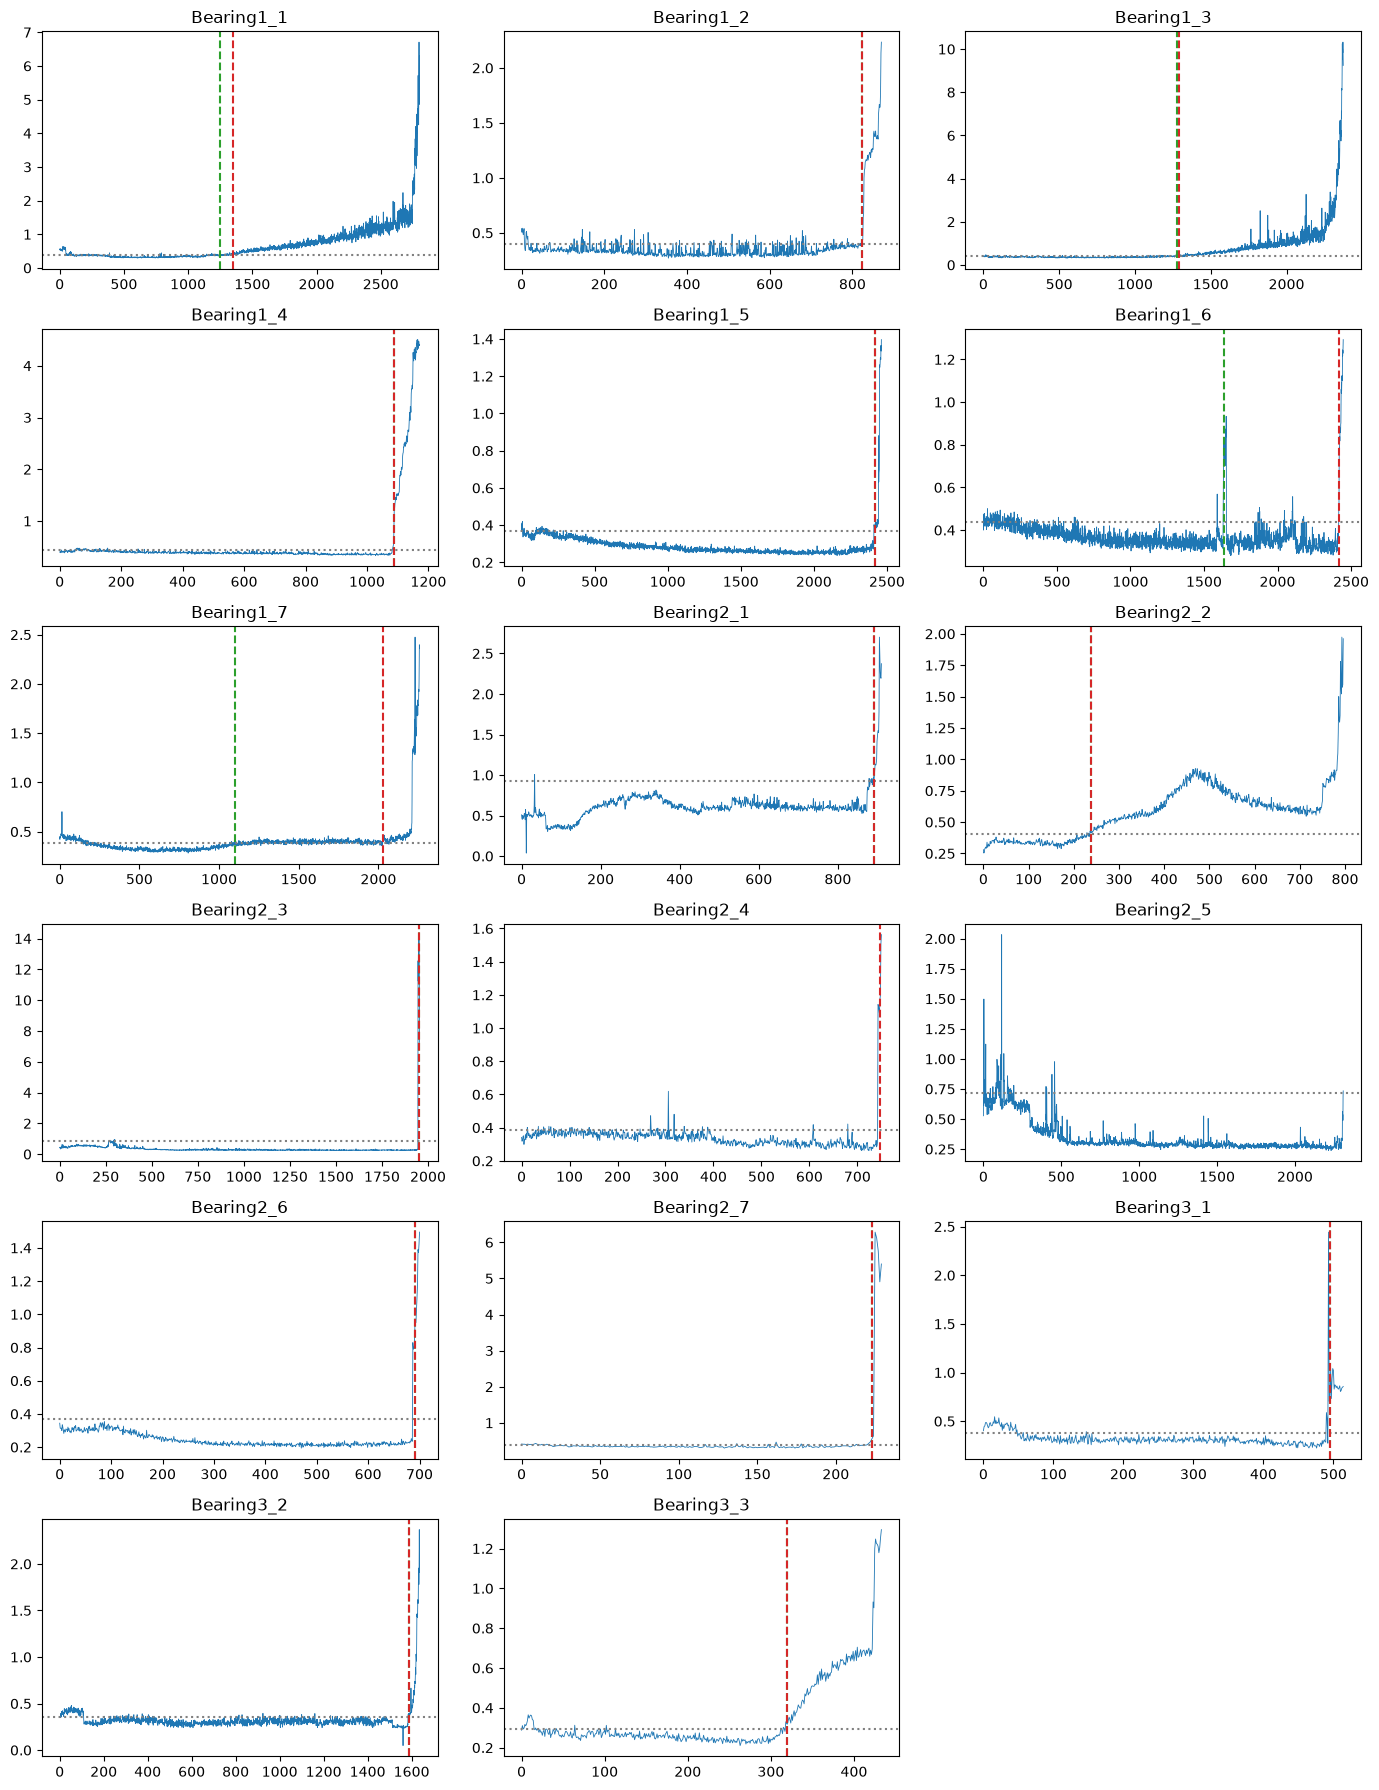

,n,M1_idx,M2_idx,M1_frac,M2_frac
Bearing1_1,2803.0,1249.0,1352.0,0.45,0.48
Bearing1_2,871.0,824.0,824.0,0.95,0.95
Bearing1_3,2375.0,1275.0,1291.0,0.54,0.54
Bearing1_4,1172.0,1087.0,1087.0,0.93,0.93
Bearing1_5,2463.0,2415.0,2415.0,0.98,0.98
Bearing1_6,2448.0,1635.0,2421.0,0.67,0.99
Bearing1_7,2259.0,1101.0,2027.0,0.49,0.90
Bearing2_1,911.0,891.0,891.0,0.98,0.98
Bearing2_2,797.0,239.0,239.0,0.30,0.30
Bearing2_3,1955.0,1950.0,1950.0,1.00,1.00


In [7]:
def fpt_candidates(rms, base=(0.10, 0.30), k=3.0, smooth=9, run=5):
    n = len(rms)
    x = pd.Series(rms).rolling(smooth, min_periods=1).median().to_numpy()
    b0, b1 = int(base[0] * n), int(base[1] * n)
    thr = x[b0:b1].mean() + k * x[b0:b1].std()
    above = x > thr
    first = next((i for i in range(b1, n - run + 1) if above[i:i + run].all()), None)
    below = np.flatnonzero(~above)
    last = int(below[-1] + 1) if len(below) and below[-1] + 1 < n else None
    return first, last, thr

res = {}
fig, axes = plt.subplots(6, 3, figsize=(14, 18))
for ax, (b, g) in zip(axes.ravel(), fem.groupby("bearing")):
    g = g.sort_values("idx")
    first, last, thr = fpt_candidates(g["rms_h"].to_numpy())
    res[b] = {"n": len(g), "M1_idx": first, "M2_idx": last}
    ax.plot(g["idx"], g["rms_h"], lw=0.6)
    ax.axhline(thr, c="grey", ls=":")
    if first is not None: ax.axvline(first, c="tab:green", ls="--")
    if last is not None: ax.axvline(last, c="tab:red", ls="--")
    ax.set_title(b)
for ax in axes.ravel()[len(res):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

out = pd.DataFrame(res).T.astype(float)
out["M1_frac"] = (out["M1_idx"] / out["n"]).round(2)
out["M2_frac"] = (out["M2_idx"] / out["n"]).round(2)
out

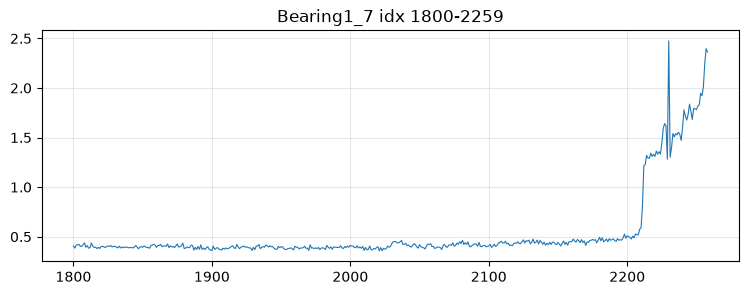

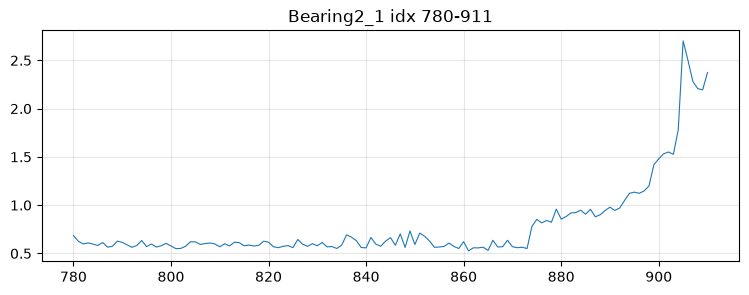

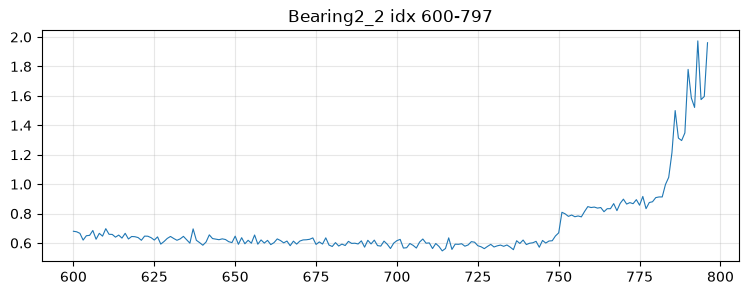

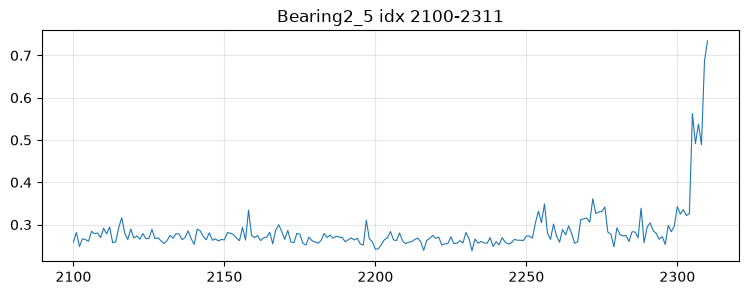

In [8]:
def zoom(b, lo, hi):
    g = fem[(fem.bearing == b) & (fem.idx.between(lo, hi))]
    plt.figure(figsize=(9, 3)); plt.plot(g["idx"], g["rms_h"], lw=0.8)
    plt.title(f"{b} idx {lo}-{hi}"); plt.grid(alpha=0.3); plt.show()

zoom("Bearing1_7", 1800, 2259)
zoom("Bearing2_1", 780, 911)
zoom("Bearing2_2", 600, 797)
zoom("Bearing2_5", 2100, 2311)

In [9]:
FPT = {"Bearing1_1": 1352, "Bearing1_2": 824, "Bearing1_3": 1291, "Bearing1_4": 1087, "Bearing1_5": 2415,
       "Bearing1_6": 2421, "Bearing1_7": None, "Bearing2_1": None, "Bearing2_2": None, "Bearing2_3": 1950,
       "Bearing2_4": 747, "Bearing2_5": None, "Bearing2_6": 691, "Bearing2_7": 223, "Bearing3_1": 495,
       "Bearing3_2": 1589, "Bearing3_3": 319}
n_all = fem.groupby("bearing")["idx"].size()
tab = pd.DataFrame({"n": n_all, "fpt": pd.Series(FPT)})
tab["post_fpt_snapshots"] = tab["n"] - tab["fpt"]
tab["frac_life_degrading"] = (tab["post_fpt_snapshots"] / tab["n"]).round(2)
tab

,n,fpt,post_fpt_snapshots,frac_life_degrading
Bearing1_1,2803,1352.0,1451.0,0.52
Bearing1_2,871,824.0,47.0,0.05
Bearing1_3,2375,1291.0,1084.0,0.46
Bearing1_4,1172,1087.0,85.0,0.07
Bearing1_5,2463,2415.0,48.0,0.02
Bearing1_6,2448,2421.0,27.0,0.01
Bearing1_7,2259,NaN,NaN,NaN
Bearing2_1,911,NaN,NaN,NaN
Bearing2_2,797,NaN,NaN,NaN
Bearing2_3,1955,1950.0,5.0,0.00


In [10]:
g = fem[(fem.bearing == "Bearing1_7") & (fem.idx >= 2150)]
print(g.loc[g.rms_h > 0.8, "idx"].min())
g[["idx", "rms_h"]].iloc[50:70]

2211


,idx,rms_h
18192,2200,0.507249
18193,2201,0.502706
18194,2202,0.492705
18195,2203,0.476723
18196,2204,0.506039
18197,2205,0.489313
18198,2206,0.528158
18199,2207,0.519939
18200,2208,0.519142
18201,2209,0.576132


In [11]:
def fpt_ratio(b, healthy, factor=1.3, smooth=5):
    g = fem[fem.bearing == b].sort_values("idx")
    x = g["rms_h"].rolling(smooth, min_periods=1).median().to_numpy()
    base = np.median(g["rms_h"].to_numpy()[healthy[0]:healthy[1]])
    above = x > factor * base
    below = np.flatnonzero(~above)
    return (int(below[-1] + 1) if len(below) and below[-1] + 1 < len(x) else None), round(float(base), 3)

for b, h in {"Bearing1_7": (1800, 2000), "Bearing2_1": (780, 860),
             "Bearing2_2": (600, 740), "Bearing2_5": (2100, 2240)}.items():
    print(b, fpt_ratio(b, h))

Bearing1_7 (2208, 0.393)
Bearing2_1 (876, 0.59)
Bearing2_2 (760, 0.61)
Bearing2_5 (2307, 0.267)


In [12]:
print(fpt_ratio("Bearing1_7", (1800, 2000)))

(2208, 0.393)


In [13]:
FPT = {"Bearing1_1": 1352, "Bearing1_2": 824, "Bearing1_3": 1291, "Bearing1_4": 1087, "Bearing1_5": 2415,
       "Bearing1_6": 2421, "Bearing1_7": 2209, "Bearing2_1": 874, "Bearing2_2": 750, "Bearing2_3": 1950,
       "Bearing2_4": 747, "Bearing2_5": 2303, "Bearing2_6": 691, "Bearing2_7": 223, "Bearing3_1": 495,
       "Bearing3_2": 1589, "Bearing3_3": 319}
n_all = fem.groupby("bearing")["idx"].size()
tab = pd.DataFrame({"n": n_all, "fpt": pd.Series(FPT)})
tab["post_fpt_snapshots"] = tab["n"] - tab["fpt"]
tab["frac_life_degrading"] = (tab["post_fpt_snapshots"] / tab["n"]).round(2)
tab

,n,fpt,post_fpt_snapshots,frac_life_degrading
Bearing1_1,2803,1352,1451,0.52
Bearing1_2,871,824,47,0.05
Bearing1_3,2375,1291,1084,0.46
Bearing1_4,1172,1087,85,0.07
Bearing1_5,2463,2415,48,0.02
Bearing1_6,2448,2421,27,0.01
Bearing1_7,2259,2209,50,0.02
Bearing2_1,911,874,37,0.04
Bearing2_2,797,750,47,0.06
Bearing2_3,1955,1950,5,0.00


In [14]:
fem["fpt_idx"] = fem["bearing"].map(FPT)
fem["post_fpt"] = fem["idx"] >= fem["fpt_idx"]
dur = (fem["t_end"] - fem["fpt_idx"] * 10.0).clip(lower=1.0)
fem["rul_frac"] = np.where(fem["post_fpt"], fem["rul_s"] / dur, 1.0)
fem[["bearing", "idx", "rul_s", "post_fpt", "rul_frac"]].groupby("bearing").tail(1)

,bearing,idx,rul_s,post_fpt,rul_frac
2802,Bearing1_1,2802,0.0,True,0.000000
3673,Bearing1_2,870,0.0,True,0.000000
4584,Bearing2_1,910,0.0,True,0.000000
5381,Bearing2_2,796,0.0,True,0.000000
5896,Bearing3_1,514,0.0,True,0.000000
7533,Bearing3_2,1636,0.0,True,0.000000
9908,Bearing1_3,2374,0.0,True,0.000000
11080,Bearing1_4,1171,9.0,True,0.010601
13543,Bearing1_5,2462,0.0,True,0.000000
15991,Bearing1_6,2447,0.0,True,0.000000


In [15]:
rows = []
for cap in [300, 600, 1200, 1800, 3600, 7200, None]:
    at_cap = fem["rul_s"] >= (cap if cap else np.inf)
    rows.append({"cap_s": cap, "share_all_at_cap": round(at_cap.mean(), 3),
                 "share_post_fpt_at_cap": round(at_cap[fem["post_fpt"]].mean(), 3)})
pd.DataFrame(rows)

,cap_s,share_all_at_cap,share_post_fpt_at_cap
0,300.0,0.979,0.877
1,600.0,0.959,0.807
2,1200.0,0.917,0.742
3,1800.0,0.876,0.703
4,3600.0,0.757,0.587
5,7200.0,0.544,0.354
6,NaN,0.000,0.000


In [16]:
fem.to_csv(DATA_PROCESSED / "femto_labeled.csv", index=False)
print(fem.shape, fem["bearing"].nunique(), "bearings")

(24633, 21) 17 bearings


In [17]:
def lobo_folds(df):
    for b in sorted(df["bearing"].unique()):
        yield b, df.index[df["bearing"] != b].to_numpy(), df.index[df["bearing"] == b].to_numpy()

rows = []
for b, tr, te in lobo_folds(fem):
    assert b not in set(fem.loc[tr, "bearing"])
    y = fem.loc[te, "rul_frac"].to_numpy(); post = fem.loc[te, "post_fpt"].to_numpy()
    pred = np.ones_like(y)               # no-skill baseline: "always healthy"
    rows.append({"bearing": b, "cond": int(fem.loc[te, "cond"].iloc[0]), "n_train": len(tr),
                 "n_test": len(te), "n_post": int(post.sum()),
                 "MAE_all": round(float(np.abs(pred - y).mean()), 3),
                 "MAE_post": round(float(np.abs(pred - y)[post].mean()), 3)})
base = pd.DataFrame(rows)
print(base.to_string(index=False))
print("macro MAE_all:", round(base.MAE_all.mean(), 3), "| macro MAE_post:", round(base.MAE_post.mean(), 3))

   bearing  cond  n_train  n_test  n_post  MAE_all  MAE_post
Bearing1_1     1    21830    2803    1451    0.259     0.500
Bearing1_2     1    23762     871      47    0.027     0.500
Bearing1_3     1    22258    2375    1084    0.228     0.500
Bearing1_4     1    23461    1172      85    0.036     0.495
Bearing1_5     1    22170    2463      48    0.010     0.500
Bearing1_6     1    22185    2448      27    0.006     0.500
Bearing1_7     1    22374    2259      50    0.011     0.500
Bearing2_1     2    23722     911      37    0.020     0.500
Bearing2_2     2    23836     797      47    0.029     0.500
Bearing2_3     2    22678    1955       5    0.001     0.500
Bearing2_4     2    23882     751       4    0.003     0.500
Bearing2_5     2    22322    2311       8    0.002     0.500
Bearing2_6     2    23932     701      10    0.007     0.500
Bearing2_7     2    24403     230       7    0.015     0.500
Bearing3_1     3    24118     515      20    0.019     0.500
Bearing3_2     3    2299

In [18]:
FEATS = ["rms_h", "kurt_h", "peak_h", "crest_h", "rms_v", "kurt_v", "peak_v", "crest_v"]
BASE_WIN = (100, 200)      # healthy reference: snapshots 100-199 (the earliest FPT is 223)
SEQ_LEN, START = 30, 200   # 30 snapshots = 5 min of history; sequences end at idx >= 200

base = fem[(fem.idx >= BASE_WIN[0]) & (fem.idx < BASE_WIN[1])].groupby("bearing")[FEATS].median()
rel = np.log(fem[FEATS].to_numpy() / base.loc[fem["bearing"]].to_numpy())
fem2 = pd.concat([fem, pd.DataFrame(rel, columns=[f"{c}_lr" for c in FEATS], index=fem.index)], axis=1)

Xs, ys, meta = [], [], []
for b, g in fem2.groupby("bearing"):
    g = g.sort_values("idx")
    a = g[[f"{c}_lr" for c in FEATS]].to_numpy(dtype=np.float32)
    for e in range(max(START, SEQ_LEN - 1), len(g)):
        Xs.append(a[e - SEQ_LEN + 1:e + 1]); ys.append(g["rul_frac"].iloc[e])
        meta.append((b, int(g["idx"].iloc[e]), bool(g["post_fpt"].iloc[e])))
X = np.stack(Xs); y = np.asarray(ys, dtype=np.float32)
meta = pd.DataFrame(meta, columns=["bearing", "idx", "post_fpt"])
print(X.shape, y.shape, int(meta.groupby("bearing").size().min()), int(meta.post_fpt.sum()), np.isfinite(X).all())

np.savez_compressed(DATA_PROCESSED / "femto_sequences.npz", X=X, y=y)
meta.to_csv(DATA_PROCESSED / "femto_sequences_meta.csv", index=False)

(21233, 30, 8) (21233,) 30 3093 True
